# VizWiz answerability: data and baselines (Project 2.2)

**Group 4**, Multimodal Data Fusion, Adelaide University, Semester 2 2026. **Part owner:** Sanjai (data and baselines).

**What this notebook does**

1. Downloads VizWiz-VQA (train, validation and test) and builds the project splits: **train = official train, dev = official validation, test = official test** (as in the proposal).
2. Builds the labels: the hard label (1 = unanswerable) and a **soft label** from the 10 crowd answers.
3. Measures photo quality (sharpness, brightness) for every photo and question frequency for every question. These give the subgroups for the sharpness-stratified and rare-question evaluation.
4. Extracts frozen **ViT-B/16** image features, **BERT-base** question features and (optional) **CLIP** reference features once, and caches them on Drive.
5. Trains, with 3 seeds each: **question-only** and **image-only** baselines, **early fusion**, **late fusion** and the **CLIP reference**, plus two floor models (majority class, photo quality only).
6. Writes everything the other parts need: `features/`, `predictions/`, `code/vizwiz_common.py` and `HANDOFF.md`.

**Where this fits in the group:** cross-attention and gated fusion (Vish), evaluation with bootstrap confidence intervals (Ruturaj) and subgroup results (Barath) all load the features and prediction files written here.

**Run it:** Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**. The first full run downloads about 20 GB of images (the pilot downloaded train and val, 14.8 GB, in about 5 min plus 4 min to unzip) and takes roughly 30-40 minutes in total. Later runs reuse the Drive cache and take a few minutes. The features need about 5 GB of Drive space.

**Quick check first:** set `CONFIG["n_per_split"] = 300` and Run all. It still downloads all the images first (about 15 min), then runs every later step on a small sample in a few minutes. Set it back to `None` for the real run; the images are already on disk, so they are not downloaded again in the same Colab session.

The answers given by crowd workers decide the label, so they are used **only** to build labels and for data analysis, never as model inputs.

## 1. Setup

All settings live in `CONFIG`.

In [1]:
import os, sys, re, json, time, shutil, subprocess, hashlib
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

CONFIG = {
    "seeds": [0, 1, 2],              # every trained baseline is run once per seed
    "sample_seed": 42,
    # Storage: features, predictions, figures and results go to Drive; images stay on local disk
    "use_drive": True,
    "drive_dir": "/content/drive/MyDrive/vizwiz_fusion",
    "local_out_dir": "/content/vizwiz_fusion",
    "data_dir": "/content/data/vizwiz",
    "download": True,
    # If the labelled test annotations come as a separate file, put its path here
    "test_annotations_path": None,
    # Quick check: rows per split (stratified). None = use everything
    "n_per_split": None,
    # Frozen encoders
    "image_model": "google/vit-base-patch16-224-in21k",
    "text_model": "bert-base-uncased",
    "use_clip": True,
    "clip_model": "openai/clip-vit-base-patch32",
    "image_size": 224,
    "image_token_grid": 7,           # 14x14 ViT patch tokens average-pooled to 7x7 = 49 region tokens
    "max_q_tokens": 40,
    "extract_batch_size": 64,
    "num_workers": 2,
    # Labels and subgroups
    "soft_label_weight": 0.5,        # train target = (1 - w) * hard label + w * share of "unanswerable" crowd votes
    "rare_question_max_count": 1,    # rare question = seen at most this many times in train
    # Speed check
    "latency_runs": 50,
}

In [2]:
import torch

IN_COLAB = "google.colab" in sys.modules
if CONFIG["use_drive"] and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path(CONFIG["drive_dir"])
else:
    OUT = Path(CONFIG["local_out_dir"])

FEAT_DIR, FIG_DIR, RES_DIR, CODE_DIR = OUT / "features", OUT / "figures", OUT / "results", OUT / "code"
DATA = Path(CONFIG["data_dir"])
for d in (FEAT_DIR, FIG_DIR, RES_DIR, CODE_DIR, DATA):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FEAS = {"device": DEVICE}
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    FEAS.update(gpu=props.name, gpu_vram_gb=round(props.total_memory / 1e9, 1))
    print(f"GPU: {props.name} ({FEAS['gpu_vram_gb']} GB)")
else:
    print("No GPU found. Use Runtime > Change runtime type > T4 GPU, then run again.")
print("Outputs ->", OUT)

Mounted at /content/drive
GPU: Tesla T4 (15.6 GB)
Outputs -> /content/drive/MyDrive/vizwiz_fusion


### Shared code for the whole group

The next cell writes `vizwiz_common.py`: data loading, the MLP head, the training loop, the threshold rule, all metrics and the prediction file format. A copy goes to `code/` on Drive. **The fusion and evaluation notebooks should import this same file**, so every model is trained and scored the same way and only the fusion method differs.

In [3]:
%%writefile vizwiz_common.py
"""Shared code for the VizWiz answerability project (Group 4).

Every model in the project (baselines AND fusion) should use the same
loading, training, threshold and metric code from this file, so that
differences between models come only from the inputs and the fusion method.

Usage in any notebook:
    import sys; sys.path.append("/content/drive/MyDrive/vizwiz_fusion/code")
    from vizwiz_common import *
    meta, feats = load_handoff("/content/drive/MyDrive/vizwiz_fusion")
"""
import copy
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, roc_auc_score)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Default training recipe (same as the pilot). Fusion models may change lr / epochs,
# but should keep the loss, early stopping rule and threshold rule.
TRAIN_CFG = {          # same as the pilot (pilot models stopped after 5-7 epochs)
    "epochs": 15,
    "batch_size": 256,
    "lr": 1e-3,
    "weight_decay": 1e-2,
    "patience": 3,
}


# ---------------------------------------------------------------- setup
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def peak_vram_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


# ---------------------------------------------------------------- data hand-off
def load_handoff(out_dir, names=None, mmap=True):
    """Load meta.csv and the cached feature arrays written by 02_data_and_baselines.

    Row i of every array matches row i of meta. Token arrays are large, so by default
    they are memory-mapped (read from disk only when a batch needs them).
    Returns (meta DataFrame, dict of name -> np.ndarray).
    """
    out_dir = Path(out_dir)
    manifest = json.loads((out_dir / "features" / "manifest.json").read_text())
    meta = pd.read_csv(out_dir / "features" / "meta.csv")
    assert len(meta) == manifest["n_rows"], "meta.csv and manifest disagree; re-run the data notebook"
    names = names or list(manifest["features"])
    feats = {}
    for n in names:
        path = out_dir / "features" / manifest["features"][n]["file"]
        feats[n] = np.load(path, mmap_mode="r" if mmap else None)
        assert len(feats[n]) == len(meta), f"{n} has {len(feats[n])} rows, meta has {len(meta)}"
    return meta, feats


def split_index(meta):
    """Row positions of each split: train = official train, dev = official val, test = official test."""
    return {s: np.where(meta["split"].values == s)[0] for s in ("train", "dev", "test")}


def vector_batch(X):
    """Batch function for one 2-D feature array (e.g. a pooled vector per pair)."""
    X = np.asarray(X)
    return lambda idx: (torch.from_numpy(np.ascontiguousarray(X[np.asarray(idx)])).to(DEVICE).float(),)


# ---------------------------------------------------------------- models
class MLPHead(nn.Module):
    """LayerNorm -> Linear -> GELU -> Dropout -> Linear. Outputs one logit."""

    def __init__(self, d_in, d_hidden=256, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d_hidden), nn.GELU(),
                                 nn.Dropout(p), nn.Linear(d_hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


# ---------------------------------------------------------------- training
@torch.no_grad()
def predict(model, get_batch, idx, bs=1024):
    """P(unanswerable) for the rows in idx, in the same order as idx."""
    model.eval()
    out = [torch.sigmoid(model(*get_batch(idx[i:i + bs]))).float().cpu() for i in range(0, len(idx), bs)]
    return torch.cat(out).numpy() if out else np.zeros(0, np.float32)


def log_loss(p, y, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())


def train_model(model, get_batch, idx_train, idx_dev, target, y_hard, seed, cfg=None):
    """Train one model and return (best model, history DataFrame, cost dict).

    target : float array over ALL rows, the training target (soft or hard label)
    y_hard : float array over ALL rows, the official 0/1 label (1 = unanswerable)
    Loss    : BCE with pos_weight = (#answerable / #unanswerable) in train, so the
              minority class is not ignored.
    Stopping: best dev AUPRC (suits imbalanced classes), patience from cfg.
    """
    cfg = {**TRAIN_CFG, **(cfg or {})}
    model = model.to(DEVICE)
    pos = float(y_hard[idx_train].mean())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - pos) / pos, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    target_t = torch.as_tensor(np.asarray(target), dtype=torch.float32)
    rng = np.random.default_rng(seed)
    probe = rng.choice(idx_train, size=min(len(idx_train), 5000), replace=False)
    hist, best_ap, best_state, bad, secs = [], -1.0, None, 0, []
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(cfg["epochs"]):
        model.train()
        t0 = time.time()
        for b in np.array_split(rng.permutation(idx_train), max(1, len(idx_train) // cfg["batch_size"])):
            loss = loss_fn(model(*get_batch(b)), target_t[torch.as_tensor(b)].to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        secs.append(time.time() - t0)
        p_tr, p_dev = predict(model, get_batch, probe), predict(model, get_batch, idx_dev)
        ap = average_precision_score(y_hard[idx_dev], p_dev)
        hist.append({"epoch": ep + 1, "train_loss": log_loss(p_tr, y_hard[probe]),
                     "dev_loss": log_loss(p_dev, y_hard[idx_dev]), "dev_auprc": ap})
        if ap > best_ap:
            best_ap, best_state, bad = ap, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    cost = {"sec_per_epoch": round(float(np.mean(secs)), 2), "epochs_run": len(hist),
            "params": int(sum(p.numel() for p in model.parameters())), "peak_vram_gb": peak_vram_gb()}
    return model, pd.DataFrame(hist), cost


# ---------------------------------------------------------------- threshold and metrics
def tune_threshold(p, y):
    """Threshold that maximises macro-F1 on dev. Always tune on dev, never on test."""
    grid = np.linspace(0.05, 0.95, 91)
    return float(grid[int(np.argmax([f1_score(y, p >= t, average="macro") for t in grid]))])


def expected_calibration_error(p, y, n_bins=15):
    """ECE with equal-width bins: average |accuracy - confidence| weighted by bin size."""
    p, y = np.asarray(p), np.asarray(y)
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def evaluate(p, y, t):
    """All project metrics for one set of probabilities p, labels y and threshold t."""
    y = np.asarray(y).astype(int)
    yhat = (np.asarray(p) >= t).astype(int)
    return {"macro_f1": f1_score(y, yhat, average="macro"),
            "f1_unanswerable": f1_score(y, yhat, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y, yhat),
            "accuracy": accuracy_score(y, yhat),
            "auroc": roc_auc_score(y, p),
            "auprc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p),
            "ece": expected_calibration_error(p, y)}


def paired_bootstrap_gain(p_a, t_a, p_b, t_b, y, n_boot=1000, seed=42):
    """95% CI of macro-F1(model a) - macro-F1(model b), resampling the same rows for both."""
    y = np.asarray(y).astype(int)
    ya, yb = (np.asarray(p_a) >= t_a).astype(int), (np.asarray(p_b) >= t_b).astype(int)
    rng = np.random.default_rng(seed)
    gains = []
    for _ in range(n_boot):
        b = rng.integers(0, len(y), len(y))
        gains.append(f1_score(y[b], ya[b], average="macro") - f1_score(y[b], yb[b], average="macro"))
    return float(np.mean(gains)), [float(x) for x in np.percentile(gains, [2.5, 97.5])]


# ---------------------------------------------------------------- shared prediction files
def save_predictions(out_dir, model_name, seed, p_dev, p_test, threshold, extra=None):
    """Write one model's predictions in the shared format the evaluation notebook reads.

    File: <out_dir>/predictions/<model_name>__seed<seed>.npz with p_dev, p_test (row order =
    split_index(meta)["dev"/"test"]), and the dev-tuned threshold.
    """
    pred_dir = Path(out_dir) / "predictions"
    pred_dir.mkdir(parents=True, exist_ok=True)
    safe = "".join(c if c.isalnum() or c in "-_" else "_" for c in model_name)
    np.savez(pred_dir / f"{safe}__seed{seed}.npz", model=model_name, seed=seed,
             p_dev=np.asarray(p_dev, np.float32), p_test=np.asarray(p_test, np.float32),
             threshold=float(threshold), extra=json.dumps(extra or {}))


def load_predictions(out_dir):
    """All saved predictions as a list of dicts (model, seed, p_dev, p_test, threshold)."""
    rows = []
    for f in sorted((Path(out_dir) / "predictions").glob("*.npz")):
        z = np.load(f, allow_pickle=False)
        rows.append({"model": str(z["model"]), "seed": int(z["seed"]), "p_dev": z["p_dev"],
                     "p_test": z["p_test"], "threshold": float(z["threshold"]),
                     "extra": json.loads(str(z["extra"]))})
    return rows

Writing vizwiz_common.py


In [4]:
shutil.copy("vizwiz_common.py", CODE_DIR / "vizwiz_common.py")
sys.path.insert(0, os.getcwd())
import importlib, vizwiz_common
importlib.reload(vizwiz_common)
from vizwiz_common import (MLPHead, evaluate, expected_calibration_error, predict,
                           save_predictions, set_seed, split_index, train_model, tune_threshold, vector_batch)

set_seed(CONFIG["sample_seed"])
print("Shared code saved to", CODE_DIR / "vizwiz_common.py")

Shared code saved to /content/drive/MyDrive/vizwiz_fusion/code/vizwiz_common.py


## 2. Download the data

VizWiz-VQA is released under CC BY 4.0 (VizWiz n.d.). Images go to local disk, and each zip is deleted after it is unzipped. A marker file records each finished step, so running this cell again skips finished downloads.

In [5]:
import requests
from tqdm.auto import tqdm

BASE_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final"
DOWNLOADS = {
    "Annotations.zip": f"{BASE_URL}/vqa_data/Annotations.zip",
    "train.zip": f"{BASE_URL}/images/train.zip",
    "val.zip": f"{BASE_URL}/images/val.zip",
    "test.zip": f"{BASE_URL}/images/test.zip",
}
DOWNLOAD_LOG = RES_DIR / "download_log.json"


def download(url, path, chunk=8 * 1024 * 1024):
    # Stream to disk with a progress bar; resume a partial file if the server allows it
    done = path.stat().st_size if path.exists() else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(url, stream=True, headers=headers, timeout=60) as r:
        if done and r.status_code != 206:
            done = 0
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) + done
        with open(path, "ab" if done else "wb") as f, tqdm(total=total, initial=done, unit="B",
                                                          unit_scale=True, desc=path.name) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))


def download_and_extract(name, url, dest):
    marker = dest / f".{name}.done"
    if marker.exists():
        print(f"{name}: already done, skipping")
        return
    print(f"{name}: {shutil.disk_usage(dest).free / 1e9:.0f} GB free on local disk")
    zpath, t0 = dest / name, time.time()
    download(url, zpath)
    size_gb, t1 = zpath.stat().st_size / 1e9, time.time()
    subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)], check=True)
    zpath.unlink()
    marker.touch()
    log = json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else {}
    log[name] = {"size_gb": round(size_gb, 2), "download_min": round((t1 - t0) / 60, 1),
                 "unzip_min": round((time.time() - t1) / 60, 1)}
    DOWNLOAD_LOG.write_text(json.dumps(log, indent=2))
    print(f"{name}: {size_gb:.1f} GB, downloaded in {(t1 - t0) / 60:.1f} min")


if CONFIG["download"]:
    for name, url in DOWNLOADS.items():
        download_and_extract(name, url, DATA)

Annotations.zip: 75 GB free on local disk


Annotations.zip:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

Annotations.zip: 0.0 GB, downloaded in 0.0 min
train.zip: 75 GB free on local disk


train.zip:   0%|          | 0.00/11.3G [00:00<?, ?B/s]

train.zip: 11.3 GB, downloaded in 8.5 min
val.zip: 64 GB free on local disk


val.zip:   0%|          | 0.00/3.49G [00:00<?, ?B/s]

val.zip: 3.5 GB, downloaded in 2.6 min
test.zip: 60 GB free on local disk


test.zip:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

test.zip: 4.0 GB, downloaded in 2.4 min


## 3. Load annotations, labels and splits

- **Hard label** `y = 1 - answerable` (1 = unanswerable). Used for model selection, thresholds and all reported metrics.
- **Vote share**: share of the 10 crowd answers that say "unanswerable" or "unsuitable".
- **Soft label** `y_soft = (1 - w) * y + w * vote_share` with `w = 0.5`. Used only as the **training target**, so the model is less sure on pairs where workers disagreed (proposal finding: many pairs are labelled answerable even though 3 or more workers said unanswerable).
- **Question frequency**: how often the normalised question appears in **train**. A question is **rare** if it was seen at most once in train. This gives the rare-question subset that separates real fusion from memorised phrasing.

If the test split has no labels, the notebook still runs: it reports dev results and tells you how to add the labelled test file.

In [6]:
UNANS_VOTES = {"unanswerable", "unsuitable", "unsuitable image"}
SPLIT_NAMES = {"train": "train", "val": "dev", "test": "test"}


def find_one(root, filename):
    hits = sorted(p for p in Path(root).rglob(filename) if "__MACOSX" not in p.parts)
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {root}. Did the Annotations.zip download finish?")
    return hits[0]


def index_images(root):
    paths = {}
    for dirpath, _, files in os.walk(root, followlinks=True):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                paths[f] = os.path.join(dirpath, f)
    return paths


def load_split(json_path, official):
    with open(json_path) as f:
        records = json.load(f)
    rows = [{"image": r["image"],
             "question": str(r.get("question", "")).strip(),
             "answers": [str(a.get("answer", "")).strip().lower() for a in (r.get("answers") or [])],
             "answer_type": r.get("answer_type"),
             "answerable": r.get("answerable"),
             "split": SPLIT_NAMES[official]} for r in records]
    print(f"{official}: {len(rows):,} records")
    return pd.DataFrame(rows)


raw = pd.concat([load_split(find_one(DATA, f"{s}.json"), s) for s in ("train", "val", "test")], ignore_index=True)

# Labelled test annotations supplied as a separate file (optional)
if CONFIG["test_annotations_path"]:
    ext = load_split(Path(CONFIG["test_annotations_path"]), "test").set_index("image")
    is_test = (raw["split"] == "test").values
    raw.loc[is_test, "answerable"] = raw.loc[is_test, "image"].map(ext["answerable"]).values
    ext_answers = ext["answers"].to_dict()
    raw["answers"] = [ext_answers.get(im, a) if t else a for im, a, t in zip(raw["image"], raw["answers"], is_test)]

raw["y"] = 1.0 - pd.to_numeric(raw["answerable"], errors="coerce")
HAS_TEST_LABELS = bool(raw.loc[raw.split == "test", "y"].notna().all() and (raw.split == "test").any())
if not HAS_TEST_LABELS:
    print("WARNING: the test split has no answerable labels. Results below use dev only.\n"
          "Download the labelled test annotations and set CONFIG['test_annotations_path'], then run again.")

IMG_INDEX = index_images(DATA)
raw["path"] = raw["image"].map(IMG_INDEX)
print(f"Images found: {len(IMG_INDEX):,}; annotation rows without an image file: {raw['path'].isna().sum()}")
raw = raw.dropna(subset=["path"]).reset_index(drop=True)
if raw.empty:
    raise RuntimeError(f"No images found under {DATA}. Check that train.zip, val.zip and test.zip finished unzipping.")

# Crowd votes -> soft label (labels only, never a model input)
raw["n_answers"] = raw["answers"].str.len()
raw["unans_votes"] = raw["answers"].apply(lambda a: sum(x in UNANS_VOTES for x in a))
raw["vote_share"] = np.where(raw["n_answers"] > 0, raw["unans_votes"] / raw["n_answers"].clip(lower=1), np.nan)
w = CONFIG["soft_label_weight"]
raw["y_soft"] = np.where(raw["vote_share"].notna(), (1 - w) * raw["y"] + w * raw["vote_share"], raw["y"])


# Question frequency in train (normalised text)
def norm_q(q):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", q.lower())).strip()


raw["q_norm"] = raw["question"].map(norm_q)
train_counts = raw.loc[raw.split == "train", "q_norm"].value_counts()
raw["q_freq_train"] = raw["q_norm"].map(train_counts).fillna(0).astype(int)
raw["rare_question"] = raw["q_freq_train"] <= CONFIG["rare_question_max_count"]
raw["q_words"] = raw["question"].str.split().str.len()


# Optional small sample for a quick check
def take(df, n, seed):
    if n is None or n >= len(df):
        return df
    if df["y"].notna().all():  # stratified by label
        return pd.concat([g.sample(max(1, round(n * len(g) / len(df))), random_state=seed)
                          for _, g in df.groupby("y")])
    return df.sample(n, random_state=seed)


order = {"train": 0, "dev": 1, "test": 2}
meta = pd.concat([take(raw[raw.split == s], CONFIG["n_per_split"], CONFIG["sample_seed"]) for s in order],
                 ignore_index=True)
meta = meta.sort_values("split", key=lambda s: s.map(order), kind="stable").reset_index(drop=True)
meta["row"] = np.arange(len(meta))
IDX = split_index(meta)
FINGERPRINT = hashlib.md5("|".join(meta["image"] + "#" + meta["question"]).encode()).hexdigest()[:12]

display(meta.groupby("split", sort=False)["y"].agg(pairs="size", unanswerable_rate="mean").round(3))
print("Feature fingerprint:", FINGERPRINT)

train: 20,523 records
val: 4,319 records
test: 8,000 records
Download the labelled test annotations and set CONFIG['test_annotations_path'], then run again.
Images found: 39,704; annotation rows without an image file: 0


,pairs,unanswerable_rate
split,,
train,20523,0.270
dev,4319,0.321
test,8000,NaN


Feature fingerprint: 895f3ed603bb


## 4. Data characterisation

Photo sharpness is the variance of the Laplacian, a standard focus measure (Pech-Pacheco et al. 2000), computed for **every** photo (not a sample), so each pair can be put in a sharpness group: **blurry / medium / sharp**, cut at the train tertiles. Sharpness is compared between answerable and unanswerable photos with a two-sided Mann-Whitney U test (Mann & Whitney 1947). The result is cached, so this only runs once.

In [7]:
from multiprocessing import Pool
from PIL import Image, ImageOps
from scipy.stats import mannwhitneyu


def image_quality(path, size=256):
    try:
        with Image.open(path) as im:
            w, h = im.size
            im.draft("L", (size, size))  # fast reduced-size JPEG decode
            g = np.asarray(ImageOps.exif_transpose(im).convert("L").resize((size, size)), dtype=np.float32)
        lap = g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4 * g[1:-1, 1:-1]
        return w, h, os.path.getsize(path) / 1024, float(lap.var()), float(g.mean()), 1
    except Exception:
        return np.nan, np.nan, np.nan, np.nan, np.nan, 0


QUAL_COLS = ["width", "height", "file_kb", "sharpness", "brightness", "readable"]
QUAL_PATH = RES_DIR / f"image_quality_{FINGERPRINT}.csv"
if QUAL_PATH.exists():
    qual = pd.read_csv(QUAL_PATH)
    print("Loaded cached photo quality")
else:
    with Pool(max(1, os.cpu_count() or 1)) as pool:
        qual = pd.DataFrame(list(tqdm(pool.imap(image_quality, meta["path"], chunksize=64),
                                      total=len(meta), desc="photo quality")), columns=QUAL_COLS)
    qual.insert(0, "image", meta["image"].values)
    qual.to_csv(QUAL_PATH, index=False)
assert (qual["image"].values == meta["image"].values).all()
for c in QUAL_COLS:
    meta[c] = qual[c].values
meta["megapixels"] = meta["width"] * meta["height"] / 1e6

# Sharpness groups cut at the train tertiles
tr_sharp = meta.loc[IDX["train"], "sharpness"].dropna()
cuts = np.quantile(tr_sharp, [1 / 3, 2 / 3])
meta["sharp_bin"] = pd.cut(meta["sharpness"].fillna(tr_sharp.median()), [-np.inf, cuts[0], cuts[1], np.inf],
                           labels=["blurry", "medium", "sharp"]).astype(str)
print(f"Unreadable photos: {int((meta['readable'] == 0).sum())}; sharpness cuts at {cuts.round(1)}")

photo quality:   0%|          | 0/32842 [00:00<?, ?it/s]

Unreadable photos: 0; sharpness cuts at [153.5 485.1]


In [8]:
LAB = {0: "answerable", 1: "unanswerable"}
tr = meta.loc[IDX["train"]]
lab = meta[meta["y"].notna()]
top_q = (tr.groupby("q_norm")["y"].agg(count="size", unanswerable_rate="mean")
         .sort_values("count", ascending=False).head(10).round(3))
mw = mannwhitneyu(tr.loc[tr.y == 0, "sharpness"].dropna(), tr.loc[tr.y == 1, "sharpness"].dropna())

STATS = {
    "n_pairs_by_split": {s: int(len(IDX[s])) for s in IDX},
    "unanswerable_rate_by_split": lab.groupby("split")["y"].mean().round(3).to_dict(),
    "ambiguous_answerable_share_train": round(float(((tr.y == 0) & (tr.unans_votes >= 3)).mean()), 3),
    "ambiguous_share_of_answerable_train": round(float((tr.loc[tr.y == 0, "unans_votes"] >= 3).mean()), 3),
    "repeated_question_share_train": round(float((tr.q_freq_train >= 2).mean()), 3),
    # Same definition as the pilot and proposal (exact lower-case text, train + dev): 57.6% in the pilot
    "duplicate_questions_share_pilot_def": round(float(
        meta.loc[np.r_[IDX["train"], IDX["dev"]], "question"].str.lower().duplicated(keep=False).mean()), 3),
    "rare_question_share_by_split": meta.groupby("split")["rare_question"].mean().round(3).to_dict(),
    "unseen_question_share_test": round(float((meta.loc[IDX["test"], "q_freq_train"] == 0).mean()), 3),
    "question_words_median": float(meta["q_words"].median()),
    "sharpness_median_by_label_train": {LAB[int(k)]: v for k, v in tr.groupby("y")["sharpness"].median().round(1).items()},
    "sharpness_mannwhitney_p_train": float(mw.pvalue),
    "unanswerable_rate_by_sharp_bin_train": tr.groupby("sharp_bin")["y"].mean().round(3).to_dict(),
    "unreadable_photos": int((meta["readable"] == 0).sum()),
    "top_questions_train": top_q.reset_index().to_dict(orient="records"),
}

# The proposal's findings table, recomputed on the full data
r = STATS["unanswerable_rate_by_split"]
findings = pd.DataFrame([
    ["Unanswerable share by split", ", ".join(f"{k} {v:.1%}" for k, v in r.items()),
     "Weighted loss (pos_weight) and dev-tuned threshold"],
    ["Answerable pairs with >= 3/10 'unanswerable' votes (train)", f"{STATS['ambiguous_answerable_share_train']:.1%} of pairs",
     "Soft labels as training target"],
    ["Train pairs whose question repeats in train", f"{STATS['repeated_question_share_train']:.1%}",
     "Question-only baseline; rare-question subset"],
    ["Test questions rare in train (<= 1 time)", f"{STATS['rare_question_share_by_split'].get('test', float('nan')):.1%}",
     "Report rare vs common results"],
    ["Sharpness, answerable vs unanswerable (train median)",
     f"{STATS['sharpness_median_by_label_train']} (p = {STATS['sharpness_mannwhitney_p_train']:.1e})",
     "Sharpness-stratified evaluation; photo-quality baseline"],
], columns=["Finding", "Value", "Mitigation"])
display(findings)
print("\nMost frequent train questions:")
display(top_q)

,Finding,Value,Mitigation
0,Unanswerable share by split,"dev 32.1%, train 27.0%",Weighted loss (pos_weight) and dev-tuned thres...
1,Answerable pairs with >= 3/10 'unanswerable' v...,12.2% of pairs,Soft labels as training target
2,Train pairs whose question repeats in train,59.4%,Question-only baseline; rare-question subset
3,Test questions rare in train (<= 1 time),46.2%,Report rare vs common results
4,"Sharpness, answerable vs unanswerable (train m...","{'answerable': 347.5, 'unanswerable': 155.8} (...",Sharpness-stratified evaluation; photo-quality...



Most frequent train questions:


,count,unanswerable_rate
q_norm,,
what is this,3078,0.115
what color is this,425,0.019
what is it,298,0.094
what is this item,270,0.130
what does this say,226,0.341
what color is this shirt,209,0.062
what s this,182,0.154
what is that,170,0.076
what is in this box,167,0.102


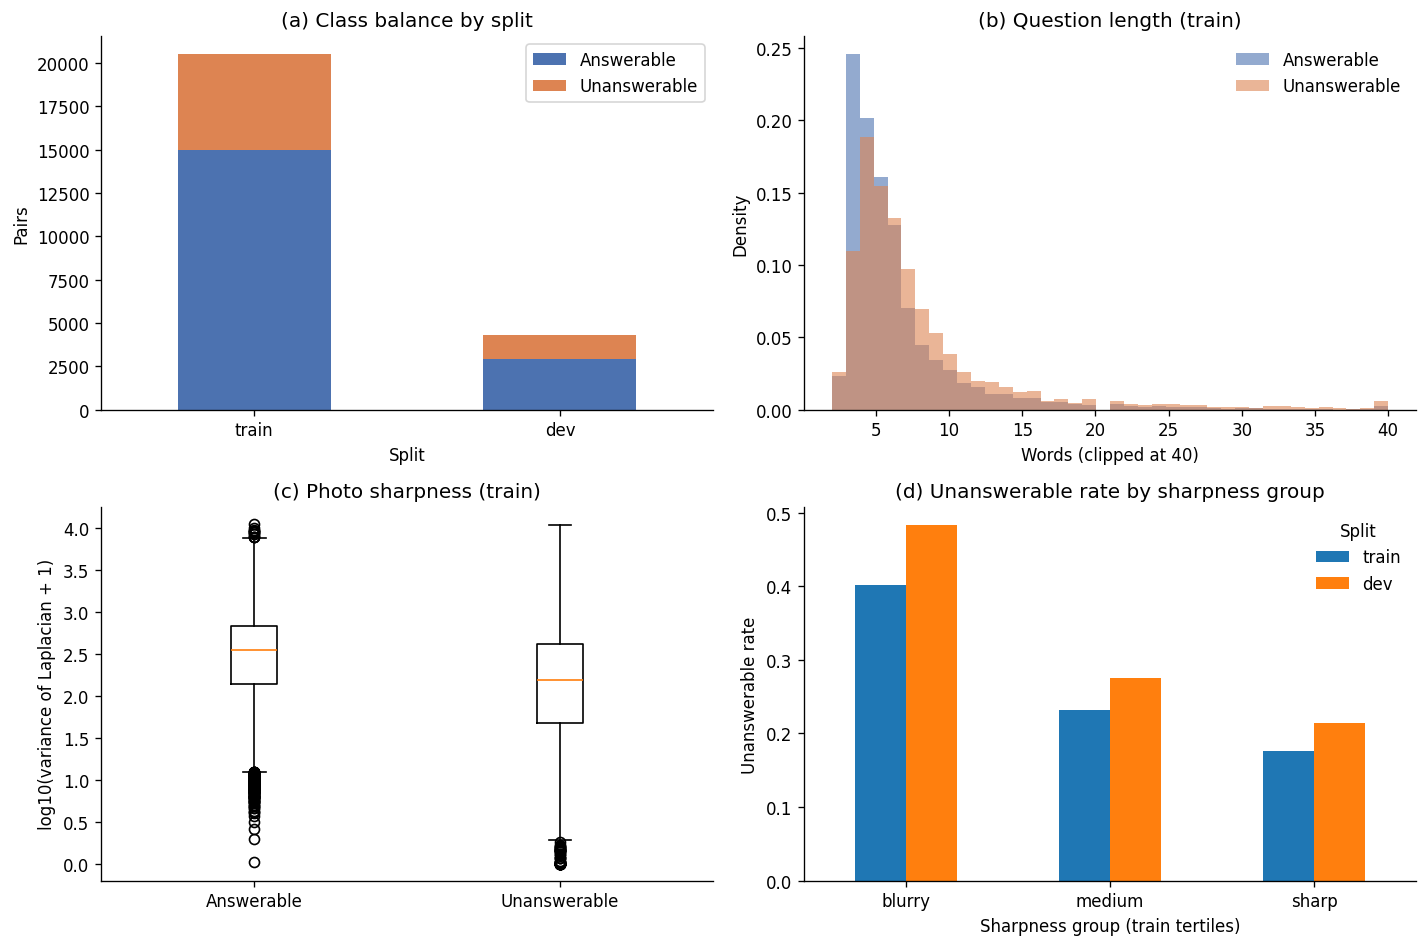

In [9]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {0: "Answerable", 1: "Unanswerable"}
COLOURS = {0: "#4C72B0", 1: "#DD8452"}
splits = [s for s in ("train", "dev", "test") if len(IDX[s])]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
counts = lab.groupby(["split", "y"]).size().unstack().reindex([s for s in splits if s in lab.split.values])
counts.columns = [LABELS[int(c)] for c in counts.columns]
counts.plot(kind="bar", stacked=True, ax=ax, color=[COLOURS[0], COLOURS[1]], rot=0)
ax.set(title="(a) Class balance by split", xlabel="Split", ylabel="Pairs")

ax = axes[0, 1]
for y in (0, 1):
    ax.hist(tr.loc[tr.y == y, "q_words"].clip(upper=40), bins=40, alpha=0.6, density=True,
            label=LABELS[y], color=COLOURS[y])
ax.set(title="(b) Question length (train)", xlabel="Words (clipped at 40)", ylabel="Density")
ax.legend(frameon=False)

ax = axes[1, 0]
ax.boxplot([np.log10(tr.loc[tr.y == y, "sharpness"].dropna() + 1) for y in (0, 1)])
ax.set_xticks([1, 2], [LABELS[0], LABELS[1]])
ax.set(title="(c) Photo sharpness (train)", ylabel="log10(variance of Laplacian + 1)")

ax = axes[1, 1]
rate = lab.groupby(["sharp_bin", "split"])["y"].mean().unstack().reindex(["blurry", "medium", "sharp"])
rate = rate[[s for s in splits if s in rate.columns]]
rate.plot(kind="bar", ax=ax, rot=0)
ax.set(title="(d) Unanswerable rate by sharpness group", xlabel="Sharpness group (train tertiles)",
       ylabel="Unanswerable rate")
ax.legend(title="Split", frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "data_characterisation.png", bbox_inches="tight")
plt.show()

## 5. Frozen feature extraction

Each encoder runs once and its output is saved to Drive straight away, so a Colab disconnect only loses the encoder that was running. Freezing pretrained encoders suits about 20,000 training pairs, which is too few to train them from scratch.

| Name | Shape | What it is |
|---|---|---|
| `img_cls` | N x 768 | ViT-B/16 [CLS] vector (Dosovitskiy et al. 2021) |
| `img_tok` | N x 49 x 768 | 14x14 patch tokens pooled to 7x7 region tokens (for cross-attention) |
| `img_ok` | N | 1 = photo read fine, 0 = unreadable (zero input) |
| `txt_cls`, `txt_mean` | N x 768 | BERT-base [CLS] and mask-aware mean (Devlin et al. 2019) |
| `txt_tok`, `txt_mask` | N x 40 x 768, N x 40 | BERT word tokens and padding mask (for cross-attention) |
| `clip_img`, `clip_txt` | N x 512 | CLIP ViT-B/32 image and text embeddings (Radford et al. 2021), reference only |

Photos get EXIF rotation and an **uncropped** 224x224 resize, because questions often ask about text near the edge of the frame. Row i of every array is row i of `meta.csv`.

In [10]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

GROUPS = {"vit": ["img_cls", "img_tok", "img_ok"],
          "bert": ["txt_cls", "txt_mean", "txt_tok", "txt_mask"],
          "clip": ["clip_img", "clip_txt"]}
DESCRIPTIONS = {
    "img_cls": "ViT-B/16 [CLS] vector", "img_tok": "ViT-B/16 7x7 region tokens", "img_ok": "1 = photo readable",
    "txt_cls": "BERT [CLS] vector", "txt_mean": "BERT mask-aware mean", "txt_tok": "BERT word tokens",
    "txt_mask": "BERT padding mask (1 = real token)", "clip_img": "CLIP image embedding",
    "clip_txt": "CLIP text embedding"}
fpath = lambda name: FEAT_DIR / f"{name}_{FINGERPRINT}.npy"
have = lambda group: all(fpath(n).exists() for n in GROUPS[group])
EXTRACTION_LOG = FEAT_DIR / f"extraction_log_{FINGERPRINT}.json"
if EXTRACTION_LOG.exists():
    FEAS.update(json.loads(EXTRACTION_LOG.read_text()))


def autocast():
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda"))


def reset_peak():
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()


def peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


def log_step(key, value):
    FEAS[key] = value
    keep = {k: FEAS[k] for k in FEAS if k.endswith("_extraction")}
    EXTRACTION_LOG.write_text(json.dumps(keep, indent=2))


def as_embedding(out):
    # transformers 4.x returns a tensor here, 5.x returns an output object
    return out if torch.is_tensor(out) else out.pooler_output


class PhotoDataset(Dataset):
    def __init__(self, paths, size, mean, std):
        self.paths, self.size = list(paths), size
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                im.draft("RGB", (self.size, self.size))
                im = ImageOps.exif_transpose(im).convert("RGB").resize((self.size, self.size),
                                                                     Image.Resampling.BICUBIC)
            x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.0).permute(2, 0, 1)
            return (x - self.mean) / self.std, 1
        except Exception:
            return torch.zeros(3, self.size, self.size), 0


def photo_loader(paths, mean, std):
    return DataLoader(PhotoDataset(paths, CONFIG["image_size"], mean, std), batch_size=CONFIG["extract_batch_size"],
                      num_workers=CONFIG["num_workers"], pin_memory=(DEVICE == "cuda"))


@torch.no_grad()
def extract_vit(paths):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    model = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    n, g, d = len(paths), CONFIG["image_token_grid"], model.config.hidden_size
    cls, tok, ok = np.empty((n, d), np.float16), np.empty((n, g * g, d), np.float16), np.empty(n, np.uint8)
    reset_peak()
    t0, i = time.time(), 0
    for x, flag in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="ViT features"):
        x = x.to(DEVICE, non_blocking=True)
        with autocast():
            h = model(pixel_values=x).last_hidden_state
        b, side = len(x), int(round((h.shape[1] - 1) ** 0.5))
        grid = h[:, 1:].float().reshape(b, side, side, d).permute(0, 3, 1, 2)
        regions = F.adaptive_avg_pool2d(grid, g).flatten(2).transpose(1, 2)
        cls[i:i + b], tok[i:i + b], ok[i:i + b] = h[:, 0].float().cpu().numpy(), regions.cpu().numpy(), flag.numpy()
        i += b
    secs = time.time() - t0
    log_step("image_extraction", {"n": n, "minutes": round(secs / 60, 1), "images_per_sec": round(n / secs, 1),
                                  "peak_vram_gb": peak_gb(), "unreadable_images": int((ok == 0).sum())})
    return {"img_cls": cls, "img_tok": tok, "img_ok": ok}


@torch.no_grad()
def extract_bert(questions):
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    model = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    n, L, d, bs = len(questions), CONFIG["max_q_tokens"], model.config.hidden_size, 2 * CONFIG["extract_batch_size"]
    cls, mean = np.empty((n, d), np.float16), np.empty((n, d), np.float16)
    tok, mask = np.empty((n, L, d), np.float16), np.empty((n, L), np.uint8)
    full_len = np.array([len(t) for t in tokenizer(questions)["input_ids"]])
    reset_peak()
    t0 = time.time()
    for i in tqdm(range(0, n, bs), desc="BERT features"):
        enc = tokenizer(questions[i:i + bs], padding="max_length", truncation=True, max_length=L,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            h = model(**enc).last_hidden_state
        h, m = h.float(), enc["attention_mask"].unsqueeze(-1).float()
        cls[i:i + bs] = h[:, 0].cpu().numpy()
        mean[i:i + bs] = ((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        tok[i:i + bs], mask[i:i + bs] = h.cpu().numpy(), enc["attention_mask"].cpu().numpy()
    log_step("text_extraction", {"n": n, "minutes": round((time.time() - t0) / 60, 1), "peak_vram_gb": peak_gb(),
                                 "truncated_share": round(float((full_len > L).mean()), 4)})
    return {"txt_cls": cls, "txt_mean": mean, "txt_tok": tok, "txt_mask": mask}


@torch.no_grad()
def extract_clip(paths, questions):
    from transformers import CLIPModel
    proc = AutoImageProcessor.from_pretrained(CONFIG["clip_model"])
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["clip_model"])
    model = CLIPModel.from_pretrained(CONFIG["clip_model"]).to(DEVICE).eval()
    img, txt = [], []
    reset_peak()
    t0 = time.time()
    for x, _ in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="CLIP image"):
        with autocast():
            img.append(as_embedding(model.get_image_features(pixel_values=x.to(DEVICE))).float().cpu().numpy())
    bs = 2 * CONFIG["extract_batch_size"]
    for i in tqdm(range(0, len(questions), bs), desc="CLIP text"):
        enc = tokenizer(questions[i:i + bs], padding=True, truncation=True, max_length=77,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            txt.append(as_embedding(model.get_text_features(**enc)).float().cpu().numpy())
    log_step("clip_extraction", {"n": len(paths), "minutes": round((time.time() - t0) / 60, 1),
                                 "peak_vram_gb": peak_gb()})
    return {"clip_img": np.concatenate(img).astype(np.float16), "clip_txt": np.concatenate(txt).astype(np.float16)}


def run_group(group, fn, *args):
    if have(group):
        print(f"{group}: cached")
        return
    arrays = fn(*args)
    for name, arr in arrays.items():
        np.save(fpath(name), arr)
    del arrays
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print(f"{group}: saved")


PATHS, QUESTIONS = meta["path"].tolist(), meta["question"].tolist()
run_group("vit", extract_vit, PATHS)
run_group("bert", extract_bert, QUESTIONS)
if CONFIG["use_clip"]:
    run_group("clip", extract_clip, PATHS, QUESTIONS)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

CLIP image:   0%|          | 0/514 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

CLIP text:   0%|          | 0/257 [00:00<?, ?it/s]

clip: saved


### Hand-off files: `meta.csv` and `manifest.json`

`meta.csv` keeps one row per pair, in feature order, with the labels and subgroup columns the evaluation part needs. It contains questions, so keep it on Drive and **do not commit it** to GitHub (ethics plan: share code, not data).

In [11]:
img_ok = np.load(fpath("img_ok"))
meta["img_ok"] = img_ok
META_COLS = ["row", "split", "image", "question", "y", "y_soft", "vote_share", "unans_votes", "answer_type",
             "q_norm", "q_words", "q_freq_train", "rare_question", "width", "height", "megapixels", "file_kb",
             "sharpness", "brightness", "sharp_bin", "readable", "img_ok"]
meta[META_COLS].to_csv(FEAT_DIR / "meta.csv", index=False)

feature_names = GROUPS["vit"] + GROUPS["bert"] + (GROUPS["clip"] if CONFIG["use_clip"] else [])
manifest = {
    "fingerprint": FINGERPRINT, "n_rows": int(len(meta)),
    "rows_by_split": {s: int(len(IDX[s])) for s in IDX}, "has_test_labels": HAS_TEST_LABELS,
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "encoders": {k: CONFIG[k] for k in ("image_model", "text_model", "clip_model", "image_size",
                                        "image_token_grid", "max_q_tokens")},
    "soft_label_weight": CONFIG["soft_label_weight"],
    "features": {},
}
for n in feature_names:
    a = np.load(fpath(n), mmap_mode="r")
    manifest["features"][n] = {"file": fpath(n).name, "shape": list(a.shape), "dtype": str(a.dtype),
                               "description": DESCRIPTIONS[n]}
(FEAT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
FEAS["features_on_disk_gb"] = round(sum(fpath(n).stat().st_size for n in feature_names) / 1e9, 2)
print(json.dumps({k: v for k, v in FEAS.items() if k.endswith("extraction") or k == "features_on_disk_gb"}, indent=2))

{
  "image_extraction": {
    "n": 32842,
    "minutes": 6.5,
    "images_per_sec": 84.3,
    "peak_vram_gb": 0.94,
    "unreadable_images": 0
  },
  "text_extraction": {
    "n": 32842,
    "minutes": 0.5,
    "peak_vram_gb": 0.78,
    "truncated_share": 0.0091
  },
  "clip_extraction": {
    "n": 32842,
    "minutes": 7.2,
    "peak_vram_gb": 0.95
  },
  "features_on_disk_gb": 4.71
}


### Encoder latency (one query, batch size 1)

The proposal sets a limit of 100 ms per query on a T4. The frozen encoders are almost all of that cost (the fusion heads add under 1M parameters), so the encoder time is measured here: read and resize one photo, run ViT-B/16, tokenise and run BERT-base. The evaluation part adds the head time on top.

In [12]:
@torch.no_grad()
def encoder_latency(n_runs):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    vit = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    bert = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    ds = PhotoDataset(PATHS, CONFIG["image_size"], proc.image_mean, proc.image_std)
    times = []
    for k in range(n_runs + 5):
        i = k % len(ds)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        x, _ = ds[i]
        enc = tokenizer([QUESTIONS[i]], truncation=True, max_length=CONFIG["max_q_tokens"],
                        return_tensors="pt").to(DEVICE)
        with autocast():
            vit(pixel_values=x.unsqueeze(0).to(DEVICE))
            bert(**enc)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        if k >= 5:  # first 5 runs are warm-up
            times.append((time.perf_counter() - t0) * 1000)
    del vit, bert
    return {"median_ms": round(float(np.median(times)), 1), "p95_ms": round(float(np.percentile(times, 95)), 1),
            "runs": n_runs, "device": FEAS.get("gpu", DEVICE)}


FEAS["encoder_latency"] = encoder_latency(CONFIG["latency_runs"])
print(FEAS["encoder_latency"], "(target: <= 100 ms per query on a T4, including the fusion head)")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'median_ms': 36.1, 'p95_ms': 64.8, 'runs': 50, 'device': 'Tesla T4'} (target: <= 100 ms per query on a T4, including the fusion head)


## 6. Baselines, early fusion, late fusion and the CLIP reference

All trained models use the same recipe from `vizwiz_common.py`: an MLP head, BCE loss with `pos_weight` for the class imbalance, AdamW (Loshchilov & Hutter 2019), early stopping on dev AUPRC (Saito & Rehmsmeier 2015), and a macro-F1 threshold tuned on dev. Each is run with **3 seeds**. The fusion levels follow Baltrusaitis, Ahuja & Morency (2019).

| Model | Input | Why |
|---|---|---|
| Majority class | nothing | Floor: always says "answerable" |
| Photo quality only | sharpness, brightness, size (logistic regression) | How far image quality alone goes (blur shortcut) |
| **Question-only (BERT)** | `txt_mean` | Question priors |
| **Image-only (ViT)** | `img_cls` | Photo content |
| **Early fusion** | `txt_mean` + `img_cls` joined, then MLP | Simplest fusion |
| **Late fusion** | weighted average of the two single-modality probabilities, weight tuned on dev | Fusion of decisions |
| **CLIP reference** | `clip_txt` + `clip_img` joined, then MLP | Same as early fusion, but with encoders trained to match images and text (Radford et al. 2021) |
| Question-only / Image-only, hard labels | as above | Check: do soft labels reduce overconfidence? |

The **best single-modality model** is picked on **dev** macro-F1. Every fusion model (here and in the cross-attention and gated notebooks) is measured against it. Confidence intervals and the full comparison come from the evaluation notebook, which reads the saved prediction files.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Y = meta["y"].values.astype(np.float32)               # NaN only for unlabelled test rows
TARGET = {"soft": meta["y_soft"].values.astype(np.float32), "hard": Y}
EVAL = "test" if HAS_TEST_LABELS else "dev"
y_dev, y_eval = Y[IDX["dev"]], Y[IDX[EVAL]]
load = lambda n: np.load(fpath(n)).astype(np.float32)
FE = {"txt_mean": load("txt_mean"), "img_cls": load("img_cls")}
FE["early"] = np.concatenate([FE["txt_mean"], FE["img_cls"]], axis=1)
if CONFIG["use_clip"]:
    FE["clip_early"] = np.concatenate([load("clip_txt"), load("clip_img")], axis=1)

UNIMODAL = ["Question-only (BERT)", "Image-only (ViT)"]
SPECS = {
    "Question-only (BERT)": ("txt_mean", "soft"),
    "Image-only (ViT)": ("img_cls", "soft"),
    "Early fusion": ("early", "soft"),
    "CLIP reference": ("clip_early", "soft"),
    "Question-only (BERT, hard labels)": ("txt_mean", "hard"),
    "Image-only (ViT, hard labels)": ("img_cls", "hard"),
}
SPECS = {k: v for k, v in SPECS.items() if v[0] in FE}

PRED, HIST, COST = {}, {}, {}
for name, (feat, labels) in SPECS.items():
    get_batch = vector_batch(FE[feat])
    for s in CONFIG["seeds"]:
        set_seed(s)
        model, hist, cost = train_model(MLPHead(FE[feat].shape[1]), get_batch, IDX["train"], IDX["dev"],
                                        TARGET[labels], Y, seed=s)
        p_dev, p_test = predict(model, get_batch, IDX["dev"]), predict(model, get_batch, IDX["test"])
        thr = tune_threshold(p_dev, y_dev)
        PRED[(name, s)] = {"dev": p_dev, "test": p_test, "thr": thr}
        HIST[(name, s)], COST[(name, s)] = hist.assign(model=name, seed=s), cost
        save_predictions(OUT, name, s, p_dev, p_test, thr, extra={"feature": feat, "labels": labels, **cost})
    print(f"{name:36s} {cost['epochs_run']:2d} epochs, {cost['sec_per_epoch']:.2f} s/epoch, "
          f"{cost['params']:,} params")

# Late fusion: w * P(question model) + (1 - w) * P(image model), w chosen on dev AUPRC, per seed
LATE_W = {}
for s in CONFIG["seeds"]:
    pq, pi = PRED[("Question-only (BERT)", s)], PRED[("Image-only (ViT)", s)]
    grid = np.linspace(0, 1, 21)
    w = float(grid[np.argmax([average_precision_score(y_dev, g * pq["dev"] + (1 - g) * pi["dev"]) for g in grid])])
    p_dev, p_test = w * pq["dev"] + (1 - w) * pi["dev"], w * pq["test"] + (1 - w) * pi["test"]
    thr = tune_threshold(p_dev, y_dev)
    PRED[("Late fusion", s)], LATE_W[s] = {"dev": p_dev, "test": p_test, "thr": thr}, w
    COST[("Late fusion", s)] = {"sec_per_epoch": 0.0, "epochs_run": 0, "params": 1, "peak_vram_gb": None}
    save_predictions(OUT, "Late fusion", s, p_dev, p_test, thr, extra={"question_weight": w})
print(f"Late fusion question weight per seed (tuned on dev): {LATE_W}")

# Majority class: constant train prior (no prediction file needed)
prior = float(Y[IDX["train"]].mean())
p_dev, p_test = np.full(len(IDX["dev"]), prior), np.full(len(IDX["test"]), prior)
PRED[("Majority class", 0)] = {"dev": p_dev, "test": p_test, "thr": tune_threshold(p_dev, y_dev)}

# Photo quality only: logistic regression on 4 quality numbers (deterministic, so one run)
q = meta[["sharpness", "brightness", "megapixels", "file_kb"]].copy()
q = q.fillna(q.iloc[IDX["train"]].median())
Xq = np.column_stack([np.log1p(q.sharpness), q.brightness, np.log(q.megapixels), np.log1p(q.file_kb)])
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(Xq[IDX["train"]], Y[IDX["train"]].astype(int))
p_dev, p_test = lr.predict_proba(Xq[IDX["dev"]])[:, 1], lr.predict_proba(Xq[IDX["test"]])[:, 1]
thr = tune_threshold(p_dev, y_dev)
PRED[("Photo quality only", 0)] = {"dev": p_dev, "test": p_test, "thr": thr}
save_predictions(OUT, "Photo quality only", 0, p_dev, p_test, thr, extra={"feature": "quality", "labels": "hard"})

pd.concat(HIST.values()).to_csv(RES_DIR / "baseline_histories.csv", index=False)
print("\nPredictions saved to", OUT / "predictions")

Question-only (BERT)                 10 epochs, 0.19 s/epoch, 198,657 params
Image-only (ViT)                      6 epochs, 0.19 s/epoch, 198,657 params
Early fusion                          9 epochs, 0.21 s/epoch, 396,801 params
CLIP reference                        9 epochs, 0.20 s/epoch, 264,705 params
Question-only (BERT, hard labels)    10 epochs, 0.18 s/epoch, 198,657 params
Image-only (ViT, hard labels)         6 epochs, 0.19 s/epoch, 198,657 params
Late fusion question weight per seed (tuned on dev): {0: 0.5, 1: 0.5, 2: 0.5}

Predictions saved to /content/drive/MyDrive/vizwiz_fusion/predictions


### Results

Mean and standard deviation over the 3 seeds. Thresholds are tuned on dev; the table is on the test split (or dev, if the test labels are missing). This is a quick check: the official comparison with bootstrap confidence intervals comes from the evaluation notebook.

In [14]:
ORDER = ["Majority class", "Photo quality only", "Question-only (BERT)", "Image-only (ViT)",
         "Late fusion", "Early fusion", "CLIP reference",
         "Question-only (BERT, hard labels)", "Image-only (ViT, hard labels)"]
ORDER = [m for m in ORDER if any(k[0] == m for k in PRED)]
FUSION = [m for m in ("Late fusion", "Early fusion", "CLIP reference") if m in ORDER]
METRICS = ["macro_f1", "auroc", "auprc", "f1_unanswerable", "balanced_acc", "brier", "ece"]


def scores(split):
    y = Y[IDX[split]]
    return pd.DataFrame([{"model": m, "seed": s, **evaluate(P[split], y, P["thr"])} for (m, s), P in PRED.items()])


def mean_sd(df):
    g = df.groupby("model")[METRICS]
    mean, sd = g.mean().reindex(ORDER), g.std().reindex(ORDER)
    table = mean.round(3).astype(str)
    for c in METRICS:
        table[c] = [f"{m:.3f}" + (f" ± {s:.3f}" if pd.notna(s) else "") for m, s in zip(mean[c], sd[c])]
    return mean, table


SC_DEV, SC_EVAL = scores("dev"), scores(EVAL)
MEAN_DEV, TABLE_DEV = mean_sd(SC_DEV)
MEAN_EVAL, TABLE_EVAL = mean_sd(SC_EVAL)
TABLE_EVAL.to_csv(RES_DIR / f"baseline_results_{EVAL}.csv")
TABLE_DEV.to_csv(RES_DIR / "baseline_results_dev.csv")
print(f"Results on {EVAL} (mean ± sd over seeds; thresholds tuned on dev)")
display(TABLE_EVAL)

# Best single-modality model, chosen on DEV
BEST_UNI = max(UNIMODAL, key=lambda m: MEAN_DEV.loc[m, "macro_f1"])
GAINS = {m: round(float(MEAN_EVAL.loc[m, "macro_f1"] - MEAN_EVAL.loc[BEST_UNI, "macro_f1"]), 4) for m in FUSION}

# Complementarity: how often is only one modality right? (mean over seeds)
comp = []
for s in CONFIG["seeds"]:
    ok = {m: (PRED[(m, s)][EVAL] >= PRED[(m, s)]["thr"]).astype(int) == y_eval.astype(int) for m in UNIMODAL}
    qok, iok = ok["Question-only (BERT)"], ok["Image-only (ViT)"]
    comp.append({"both_correct": (qok & iok).mean(), "only_question_correct": (qok & ~iok).mean(),
                 "only_image_correct": (~qok & iok).mean(), "both_wrong": (~qok & ~iok).mean(),
                 "exactly_one_correct": (qok ^ iok).mean(), "oracle_accuracy": (qok | iok).mean()})
COMPLEMENT = {k: round(float(v), 3) for k, v in pd.DataFrame(comp).mean().items()}

print(f"\nBest single-modality model (picked on dev): {BEST_UNI}")
print(f"Mean macro-F1 gain over it on {EVAL}:", GAINS)
print("Complementarity:", COMPLEMENT)

Results on dev (mean ± sd over seeds; thresholds tuned on dev)


,macro_f1,auroc,auprc,f1_unanswerable,balanced_acc,brier,ece
model,,,,,,,
Majority class,0.405,0.500,0.321,0.000,0.500,0.220,0.051
Photo quality only,0.622,0.663,0.506,0.485,0.622,0.225,0.158
Question-only (BERT),0.660 ± 0.003,0.735 ± 0.002,0.569 ± 0.002,0.549 ± 0.005,0.665 ± 0.001,0.208 ± 0.011,0.149 ± 0.036
Image-only (ViT),0.688 ± 0.005,0.771 ± 0.004,0.623 ± 0.003,0.580 ± 0.011,0.690 ± 0.007,0.198 ± 0.003,0.149 ± 0.010
Late fusion,0.740 ± 0.003,0.832 ± 0.002,0.699 ± 0.001,0.651 ± 0.019,0.744 ± 0.014,0.186 ± 0.007,0.167 ± 0.015
Early fusion,0.769 ± 0.002,0.865 ± 0.003,0.753 ± 0.004,0.689 ± 0.002,0.772 ± 0.002,0.150 ± 0.010,0.098 ± 0.038
CLIP reference,0.792 ± 0.002,0.892 ± 0.000,0.800 ± 0.003,0.718 ± 0.006,0.793 ± 0.008,0.141 ± 0.006,0.111 ± 0.019
"Question-only (BERT, hard labels)",0.663 ± 0.000,0.735 ± 0.001,0.569 ± 0.001,0.543 ± 0.002,0.663 ± 0.001,0.208 ± 0.008,0.149 ± 0.029
"Image-only (ViT, hard labels)",0.685 ± 0.004,0.765 ± 0.003,0.617 ± 0.003,0.573 ± 0.014,0.686 ± 0.008,0.197 ± 0.004,0.133 ± 0.012



Best single-modality model (picked on dev): Image-only (ViT)
Mean macro-F1 gain over it on dev: {'Late fusion': 0.0518, 'Early fusion': 0.0809, 'CLIP reference': 0.1033}
Complementarity: {'both_correct': 0.513, 'only_question_correct': 0.183, 'only_image_correct': 0.213, 'both_wrong': 0.091, 'exactly_one_correct': 0.396, 'oracle_accuracy': 0.909}


### Check: soft labels vs hard labels

The proposal says soft labels make the model less overconfident. Lower **Brier score** and **ECE** (expected calibration error) mean better-calibrated probabilities. Macro-F1 should stay about the same.

Note: `pos_weight` pushes every model's probabilities upwards, so the absolute ECE values look high. Compare ECE only between models trained the same way (as here: same loss, only the target changes).

In [15]:
rows = []
for base, enc in (("Question-only", "BERT"), ("Image-only", "ViT")):
    soft, hard = f"{base} ({enc})", f"{base} ({enc}, hard labels)"
    if hard not in MEAN_EVAL.index:
        continue
    for c in ("macro_f1", "auprc", "brier", "ece"):
        rows.append({"model": soft, "metric": c, "hard labels": MEAN_EVAL.loc[hard, c],
                     "soft labels": MEAN_EVAL.loc[soft, c],
                     "soft - hard": MEAN_EVAL.loc[soft, c] - MEAN_EVAL.loc[hard, c]})
ABLATION = pd.DataFrame(rows).round(4)
ABLATION.to_csv(RES_DIR / "ablation_soft_labels.csv", index=False)
display(ABLATION)

,model,metric,hard labels,soft labels,soft - hard
0,Question-only (BERT),macro_f1,0.6634,0.6597,-0.0037
1,Question-only (BERT),auprc,0.5690,0.5694,0.0004
2,Question-only (BERT),brier,0.2081,0.2079,-0.0002
3,Question-only (BERT),ece,0.1491,0.1489,-0.0002
4,Image-only (ViT),macro_f1,0.6852,0.6884,0.0031
5,Image-only (ViT),auprc,0.6169,0.6226,0.0057
6,Image-only (ViT),brier,0.1969,0.1982,0.0013
7,Image-only (ViT),ece,0.1334,0.1490,0.0156


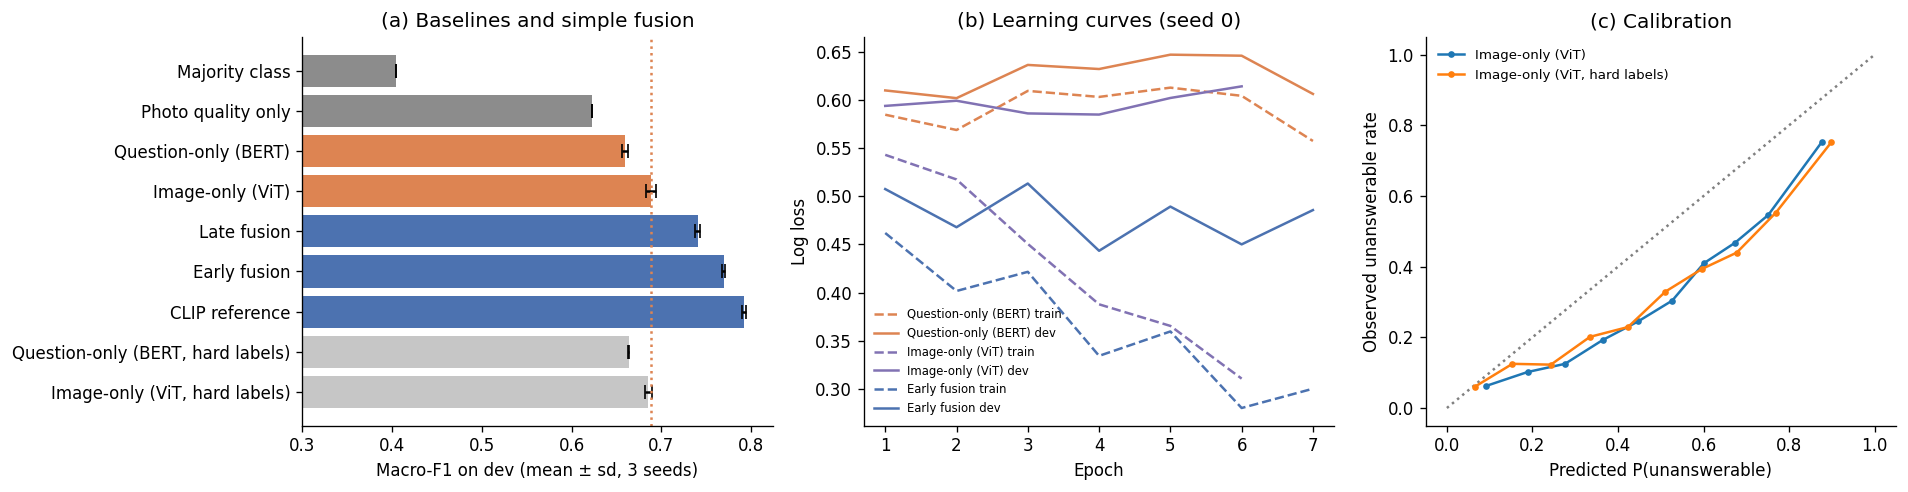

In [16]:
from sklearn.calibration import calibration_curve

s0 = CONFIG["seeds"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) model comparison
ax = axes[0]
mean = MEAN_EVAL["macro_f1"].reindex(ORDER)
sd = SC_EVAL.groupby("model")["macro_f1"].std().reindex(ORDER).fillna(0)
colours = ["#8C8C8C" if m in ("Majority class", "Photo quality only") else "#DD8452" if m in UNIMODAL
           else "#4C72B0" if m in FUSION else "#C6C6C6" for m in ORDER]
ax.barh(ORDER, mean, xerr=sd, capsize=4, color=colours)
ax.axvline(MEAN_EVAL.loc[BEST_UNI, "macro_f1"], ls=":", color="#DD8452")
ax.invert_yaxis()
ax.set(xlabel=f"Macro-F1 on {EVAL} (mean ± sd, 3 seeds)", title="(a) Baselines and simple fusion",
       xlim=(0.3, min(1.0, float((mean + sd).max()) + 0.03)))

# (b) learning curves, seed 0
ax = axes[1]
for m, c in zip(UNIMODAL + ["Early fusion"], ("#DD8452", "#8172B3", "#4C72B0")):
    h = HIST[(m, s0)]
    ax.plot(h.epoch, h.train_loss, "--", color=c, label=f"{m} train")
    ax.plot(h.epoch, h.dev_loss, "-", color=c, label=f"{m} dev")
ax.set(xlabel="Epoch", ylabel="Log loss", title="(b) Learning curves (seed 0)")
ax.legend(frameon=False, fontsize=7)

# (c) calibration: hard vs soft labels, image-only
ax = axes[2]
ax.plot([0, 1], [0, 1], ":", color="grey")
for m in ("Image-only (ViT)", "Image-only (ViT, hard labels)"):
    if (m, s0) in PRED:
        frac, conf = calibration_curve(y_eval, PRED[(m, s0)][EVAL], n_bins=10, strategy="quantile")
        ax.plot(conf, frac, marker="o", ms=3, label=m)
ax.set(xlabel="Predicted P(unanswerable)", ylabel="Observed unanswerable rate", title="(c) Calibration")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "baselines.png", bbox_inches="tight")
plt.show()

## 7. Summary and hand-off

Writes `results/baselines_summary.json` (all numbers for the report) and `HANDOFF.md` (how the other parts load the data and predictions).

In [17]:
def to_py(o):
    return o.item() if hasattr(o, "item") else str(o)


if DOWNLOAD_LOG.exists():
    FEAS["downloads"] = json.loads(DOWNLOAD_LOG.read_text())
SUMMARY = {
    "config": CONFIG, "eval_split": EVAL, "has_test_labels": HAS_TEST_LABELS, "data": STATS,
    "results_eval": MEAN_EVAL.round(4).reset_index().to_dict(orient="records"),
    "results_dev": MEAN_DEV.round(4).reset_index().to_dict(orient="records"),
    "best_unimodal": BEST_UNI, "best_unimodal_dev_macro_f1": round(float(MEAN_DEV.loc[BEST_UNI, "macro_f1"]), 4),
    "best_unimodal_eval_macro_f1": round(float(MEAN_EVAL.loc[BEST_UNI, "macro_f1"]), 4),
    "fusion_gain_vs_best_unimodal": GAINS, "late_fusion_question_weight": LATE_W,
    "complementarity": COMPLEMENT, "ablation_soft_labels": ABLATION.to_dict(orient="records"),
    "feasibility": FEAS, "training_cost": {f"{m} seed {s}": c for (m, s), c in COST.items()},
}
(RES_DIR / "baselines_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=to_py))

r = STATS["unanswerable_rate_by_split"]
bu = MEAN_EVAL.loc[BEST_UNI]
lat = FEAS.get("encoder_latency", {})
print("=== Numbers for the report ===")
print(f"Data: train {len(IDX['train']):,} / dev {len(IDX['dev']):,} / test {len(IDX['test']):,} pairs; "
      f"unanswerable " + ", ".join(f"{k} {v:.1%}" for k, v in r.items()) + ".")
print(f"Soft labels: {STATS['ambiguous_answerable_share_train']:.1%} of train pairs are labelled answerable "
      f"with >= 3/10 'unanswerable' votes.")
print(f"Questions: {STATS['duplicate_questions_share_pilot_def']:.1%} of train + dev pairs repeat another pair's "
      f"exact question (proposal: 57.6%); {STATS['repeated_question_share_train']:.1%} of train pairs repeat a train question; "
      f"{STATS['rare_question_share_by_split'].get('test', float('nan')):.1%} of test questions are rare in train.")
print(f"Photos: unanswerable rate blurry/medium/sharp (train) = {STATS['unanswerable_rate_by_sharp_bin_train']}; "
      f"Mann-Whitney p = {STATS['sharpness_mannwhitney_p_train']:.1e}; unreadable photos {STATS['unreadable_photos']}.")
print(f"Text: {FEAS.get('text_extraction', {}).get('truncated_share', float('nan')):.2%} of questions cut at "
      f"{CONFIG['max_q_tokens']} tokens.")
print(f"Best single-modality model: {BEST_UNI}, macro-F1 {bu.macro_f1:.3f}, AUROC {bu.auroc:.3f}, "
      f"AUPRC {bu.auprc:.3f} on {EVAL}.")
for m in FUSION:
    e = MEAN_EVAL.loc[m]
    print(f"{m}: macro-F1 {e.macro_f1:.3f} ({GAINS[m]:+.3f} vs best single), AUROC {e.auroc:.3f}, AUPRC {e.auprc:.3f}.")
print(f"Complementarity: exactly one modality right on {COMPLEMENT['exactly_one_correct']:.1%} of {EVAL} pairs; "
      f"oracle accuracy {COMPLEMENT['oracle_accuracy']:.1%}.")
print(f"Compute: image features {FEAS.get('image_extraction', {}).get('minutes')} min; features on disk "
      f"{FEAS.get('features_on_disk_gb')} GB; encoders {lat.get('median_ms')} ms median per query "
      f"(p95 {lat.get('p95_ms')} ms) on {lat.get('device')}.")

=== Numbers for the report ===
Data: train 20,523 / dev 4,319 / test 8,000 pairs; unanswerable dev 32.1%, train 27.0%.
Soft labels: 12.2% of train pairs are labelled answerable with >= 3/10 'unanswerable' votes.
Questions: 57.6% of train + dev pairs repeat another pair's exact question (proposal: 57.6%); 59.4% of train pairs repeat a train question; 46.2% of test questions are rare in train.
Photos: unanswerable rate blurry/medium/sharp (train) = {'blurry': 0.402, 'medium': 0.231, 'sharp': 0.176}; Mann-Whitney p = 1.1e-244; unreadable photos 0.
Text: 0.91% of questions cut at 40 tokens.
Best single-modality model: Image-only (ViT), macro-F1 0.688, AUROC 0.771, AUPRC 0.623 on dev.
Late fusion: macro-F1 0.740 (+0.052 vs best single), AUROC 0.832, AUPRC 0.699.
Early fusion: macro-F1 0.769 (+0.081 vs best single), AUROC 0.865, AUPRC 0.753.
CLIP reference: macro-F1 0.792 (+0.103 vs best single), AUROC 0.892, AUPRC 0.800.
Complementarity: exactly one modality right on 39.6% of dev pairs; ora

In [18]:
MODELS_SAVED = ", ".join(sorted({m for m, _ in PRED if m != "Majority class"}))
HANDOFF = f'''# Hand-off from data and baselines (Sanjai)

Generated {time.strftime("%Y-%m-%d %H:%M")}. Feature fingerprint `{FINGERPRINT}`. Eval split: **{EVAL}**.
Rows: train {len(IDX["train"]):,} / dev {len(IDX["dev"]):,} / test {len(IDX["test"]):,}.

## Load the data (fusion, evaluation, bias)
Add a shortcut to the shared `vizwiz_fusion` folder inside My Drive, so the path is the same for everyone.
```python
import sys; sys.path.append("{CONFIG["drive_dir"]}/code")
from vizwiz_common import *
meta, feats = load_handoff("{CONFIG["drive_dir"]}")   # token arrays are memory-mapped
IDX = split_index(meta)                                    # train / dev / test row positions
Y = meta["y"].values.astype("float32")                     # hard label, 1 = unanswerable
TARGET = meta["y_soft"].values.astype("float32")           # soft label: the training target
```

## Files
- `features/meta.csv`: one row per pair. Subgroup columns for the bias part: `sharp_bin` (blurry/medium/sharp),
  `rare_question`, `q_freq_train`, `answer_type`. Contains questions, so do not commit it to GitHub.
- `features/manifest.json`: feature arrays, shapes and encoders.
- `features/*.npy`: {", ".join(feature_names)}
- `predictions/*.npz`: one file per model and seed with `p_dev`, `p_test` and the dev-tuned `threshold`.
  Row order = `IDX["dev"]` and `IDX["test"]`. Models: {MODELS_SAVED}.
- `results/baselines_summary.json`, `results/baseline_results_{EVAL}.csv`,
  `figures/data_characterisation.png`, `figures/baselines.png`.

## Rules so results are comparable
- Train on `train`, select and tune on `dev`, use `test` only for final numbers.
- Soft label as the training target, hard label `y` for every metric.
- BCE with pos_weight, early stopping on dev AUPRC, threshold tuned on dev for macro-F1, seeds {CONFIG["seeds"]}.
- Never use answers, answer_type, vote_share or unans_votes as model inputs (they leak the label).

## The bar to beat
Best single-modality model (picked on dev): **{BEST_UNI}**, macro-F1 {MEAN_EVAL.loc[BEST_UNI, "macro_f1"]:.3f},
AUROC {MEAN_EVAL.loc[BEST_UNI, "auroc"]:.3f}, AUPRC {MEAN_EVAL.loc[BEST_UNI, "auprc"]:.3f} on {EVAL}.
Early fusion {MEAN_EVAL.loc["Early fusion", "macro_f1"]:.3f}, late fusion {MEAN_EVAL.loc["Late fusion", "macro_f1"]:.3f}.
'''
(OUT / "HANDOFF.md").write_text(HANDOFF)
print(HANDOFF)

# Hand-off from data and baselines (Sanjai)

Generated 2026-10-26 04:29. Feature fingerprint `895f3ed603bb`. Eval split: **dev**.
Rows: train 20,523 / dev 4,319 / test 8,000.

## Load the data (fusion, evaluation, bias)
Add a shortcut to the shared `vizwiz_fusion` folder inside My Drive, so the path is the same for everyone.
```python
import sys; sys.path.append("/content/drive/MyDrive/vizwiz_fusion/code")
from vizwiz_common import *
meta, feats = load_handoff("/content/drive/MyDrive/vizwiz_fusion")   # token arrays are memory-mapped
IDX = split_index(meta)                                    # train / dev / test row positions
Y = meta["y"].values.astype("float32")                     # hard label, 1 = unanswerable
TARGET = meta["y_soft"].values.astype("float32")           # soft label: the training target
```

## Files
- `features/meta.csv`: one row per pair. Subgroup columns for the bias part: `sharp_bin` (blurry/medium/sharp),
  `rare_question`, `q_freq_train`, `answer_type`. Contain

## References

Baltrusaitis, T, Ahuja, C & Morency, L-P 2019, 'Multimodal machine learning: a survey and taxonomy', *IEEE Transactions on Pattern Analysis and Machine Intelligence*, vol. 41, no. 2, pp. 423-443.

Devlin, J, Chang, M-W, Lee, K & Toutanova, K 2019, 'BERT: pre-training of deep bidirectional transformers for language understanding', in *Proceedings of the 2019 conference of the North American chapter of the Association for Computational Linguistics: human language technologies*, vol. 1, Association for Computational Linguistics, Minneapolis, USA, pp. 4171-4186.

Dosovitskiy, A, Beyer, L, Kolesnikov, A, Weissenborn, D, Zhai, X, Unterthiner, T, Dehghani, M, Minderer, M, Heigold, G, Gelly, S, Uszkoreit, J & Houlsby, N 2021, 'An image is worth 16x16 words: transformers for image recognition at scale', in *International conference on learning representations (ICLR 2021)*, online.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Loshchilov, I & Hutter, F 2019, 'Decoupled weight decay regularization', in *International conference on learning representations (ICLR 2019)*, New Orleans, USA.

Mann, HB & Whitney, DR 1947, 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, vol. 18, no. 1, pp. 50-60.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, vol. 3, IEEE, Barcelona, Spain, pp. 314-317.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

Saito, T & Rehmsmeier, M 2015, 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLOS ONE*, vol. 10, no. 3, e0118432.

VizWiz n.d., *Visual question answering*, VizWiz, viewed 26 October 2026, <https://vizwiz.org/tasks-and-datasets/vqa/>.